# 五个指数的日度开盘价、收盘价和成交量（2005—2025）

读取本 Notebook 所在文件夹的 5 个 Excel 文件，筛选 `2005-01-01` 至 `2025-12-31`（含两端），并生成五个单独的 DataFrame 和一个合并后的 `df`。

| DataFrame 名称 | 原文件代码 | 指数 |
|---|---|---|
| `CSI_Dividend` | `000922.CSI` | 中证红利指数 |
| `CSI_300` | `000300.SH` | 沪深300指数 |
| `CSI_500` | `000905.SH` | 中证500指数 |
| `CSI_1000` | `000852.SH` | 中证1000指数 |
| `Wind_All_A` | `881001.WI` | 万得全A指数 |

字段 `open`、`close` 的单位为指数点；`volume_10k_shares` 来自原表“成交量(万股)”，单位为**万股**。仅保留源文件中的交易日，不补充非交易日。某些指数的历史记录可能早于其正式发布日期；这里按所给 Excel 原样提取，不另行推算。

代码核对：[中证指数官网](https://www.csindex.com.cn/)（000300、000905、000852、000922）、[中证红利编制方案](https://oss-ch.csindex.com.cn/static/html/csindex/public/uploads/indices/detail/files/zh_CN/20231208175433-000922_Index_Methodology_cn.pdf)、[Wind 指数介绍](https://www.wind.com.cn/portal/zh/WindIndex/index.html)。Wind 的精确代码采用所给文件名 `881001.WI`。

In [1]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path.cwd()  # 从包含 5 个 Excel 文件的文件夹启动 Jupyter
START_DATE = pd.Timestamp('2005-01-01')
END_DATE = pd.Timestamp('2025-12-31')

INDEX_SPECS = {
    'CSI_Dividend': {'code': '000922.CSI', 'name_zh': '中证红利指数'},
    'CSI_300': {'code': '000300.SH', 'name_zh': '沪深300指数'},
    'CSI_500': {'code': '000905.SH', 'name_zh': '中证500指数'},
    'CSI_1000': {'code': '000852.SH', 'name_zh': '中证1000指数'},
    'Wind_All_A': {'code': '881001.WI', 'name_zh': '万得全A指数'},
}

COLUMN_MAP = {
    '交易日期': 'date',
    '开盘点位': 'open',
    '收盘价': 'close',
    '成交量(万股)': 'volume_10k_shares',
}
VALUE_COLUMNS = ['open', 'close', 'volume_10k_shares']

In [2]:
def load_index(code: str) -> pd.DataFrame:
    matches = sorted(DATA_DIR.glob(f'{code}-*.xlsx'))
    if len(matches) != 1:
        raise FileNotFoundError(f'{code}: 预期恰好 1 个 Excel 文件，实际找到 {len(matches)} 个')

    raw = pd.read_excel(matches[0], sheet_name='Sheet', usecols=list(COLUMN_MAP), dtype=str)
    frame = raw.rename(columns=COLUMN_MAP)
    frame['date'] = pd.to_datetime(frame['date'], errors='raise').dt.normalize()
    frame = frame.loc[frame['date'].between(START_DATE, END_DATE)].copy()

    for column in VALUE_COLUMNS:
        frame[column] = pd.to_numeric(
            frame[column].str.replace(',', '', regex=False).str.strip(),
            errors='raise',
        )

    if frame.empty:
        raise ValueError(f'{code}: 指定日期范围内没有数据')
    if frame['date'].duplicated().any():
        raise ValueError(f'{code}: 存在重复交易日期')
    if frame[VALUE_COLUMNS].isna().any().any():
        raise ValueError(f'{code}: 开盘价、收盘价或成交量存在缺失值')

    return frame[['date', *VALUE_COLUMNS]].sort_values('date').reset_index(drop=True)

In [3]:
frames = {key: load_index(spec['code']) for key, spec in INDEX_SPECS.items()}

CSI_Dividend = frames['CSI_Dividend']
CSI_300 = frames['CSI_300']
CSI_500 = frames['CSI_500']
CSI_1000 = frames['CSI_1000']
Wind_All_A = frames['Wind_All_A']

df = pd.concat(
    [frame.assign(index_name=key, index_code=INDEX_SPECS[key]['code'])
     for key, frame in frames.items()],
    ignore_index=True,
)[['date', 'index_name', 'index_code', *VALUE_COLUMNS]]
df = df.sort_values(['date', 'index_name']).reset_index(drop=True)

summary = (df.groupby('index_name', sort=False)
           .agg(rows=('date', 'size'), first_date=('date', 'min'),
                last_date=('date', 'max'))
           .reindex(INDEX_SPECS))
summary

,rows,first_date,last_date
index_name,,,
CSI_Dividend,5101,2005-01-04,2025-12-31
CSI_300,5101,2005-01-04,2025-12-31
CSI_500,5101,2005-01-04,2025-12-31
CSI_1000,5101,2005-01-04,2025-12-31
Wind_All_A,5101,2005-01-04,2025-12-31


In [4]:
# 合并后的长表：每行对应一个指数在一个交易日的记录。
print(f'合并后：{len(df):,} 行，{len(INDEX_SPECS)} 个指数')
df.head(10)

合并后：25,505 行，5 个指数


,date,index_name,index_code,open,close,volume_10k_shares
0,2005-01-04,CSI_1000,000852.SH,996.28,989.98,4947.38
1,2005-01-04,CSI_300,000300.SH,994.77,982.79,74128.69
2,2005-01-04,CSI_500,000905.SH,996.68,986.93,23237.62
3,2005-01-04,CSI_Dividend,000922.CSI,996.38,981.56,18030.26
4,2005-01-04,Wind_All_A,881001.WI,767.15,760.89,120818.11
5,2005-01-05,CSI_1000,000852.SH,989.87,1013.58,8226.61
6,2005-01-05,CSI_300,000300.SH,981.58,992.56,71191.09
7,2005-01-05,CSI_500,000905.SH,986.57,1003.63,34861.01
8,2005-01-05,CSI_Dividend,000922.CSI,981.11,986.54,16464.96
9,2005-01-05,Wind_All_A,881001.WI,759.99,770.89,137313.15


In [5]:
# 使用示例：查看单个指数，或按日期和指数定位合并表。
CSI_Dividend.head()
# df.set_index(['date', 'index_name']).loc[('2025-12-31', 'CSI_300')]

,date,open,close,volume_10k_shares
0,2005-01-04,996.38,981.56,18030.26
1,2005-01-05,981.11,986.54,16464.96
2,2005-01-06,987.01,975.53,16006.31
3,2005-01-07,975.58,980.72,17400.62
4,2005-01-10,979.75,989.53,14784.33


## 年度轮动策略回测

**每个自然年单独重置净值（2005—2025）。** 仅 2005 年的前 20 个交易日不交易，日终净值为 1.00。从 2005 年第 21 个交易日起，以及 2006 年及以后每年的首个交易日起，均用**当日之前最近 20 个交易日**的 B/S 标签决定持仓；这 20 日可以跨越年末，不使用当日收盘信息。每年初资金重新设为 1.00，2006 年及以后首日即建仓。

- 单个指数日收益率 = 当日收盘价 / 上一交易日收盘价 − 1。年初首个交易日的收益率使用上一年末的收盘价；2005 年首日使用源文件中 2004-12-31 的收盘价，仅用于信号计算。
- 大盘组合当日收益率 = (`CSI_300` 收益率 + `CSI_Dividend` 收益率) / 2；小盘组合当日收益率 = (`CSI_500` 收益率 + `CSI_1000` 收益率) / 2。前者严格大于后者记为 `B`，否则记为 `S`。
- 若此前 20 日 `B > S`，当天开盘后持有 `CSI_300` 与 `CSI_Dividend` 各 50%；否则持有 `CSI_500` 与 `CSI_1000` 各 50%。仅在首次建仓或切换组合时，将新组合的两只指数各配 50%；信号未变时保持份额不变，权重可随价格漂移。收盘按指数点位计价，持仓隔夜延续。
- 买入和卖出成交金额分别收取 **0.015%**（费率 `0.00015`）。年初建仓计买入费；只有切换组合时才按实际买卖金额计费，同一组合继续持有的日期不交易、无费用。期末只按收盘价计值，不额外假设清仓。

`strategy_df` 包含每个交易日的信号、回溯计数、交易金额、成本、收益率和净值；`annual_summary` 汇总每年结果。成交量字段不参与本策略计算。

In [23]:
import numpy as np

ASSETS = list(INDEX_SPECS)
LOOKBACK_DAYS = 20
TRADE_FEE_RATE = 0.00015
TEST_PERIODS = [(f'{year}-01-01', f'{year}-12-31') for year in range(2005, 2026)]

open_prices = df.pivot(index='date', columns='index_name', values='open').reindex(columns=ASSETS)
close_prices = df.pivot(index='date', columns='index_name', values='close').reindex(columns=ASSETS)
if open_prices.isna().any().any() or close_prices.isna().any().any():
    raise ValueError('五个指数的交易日期或开收盘价不齐全')
if (open_prices <= 0).any().any() or (close_prices <= 0).any().any():
    raise ValueError('指数开收盘点位必须为正')

# 仅补足区间首日计算收盘到收盘收益率所需的前一日收盘价。
previous_closes = {}
first_date = close_prices.index.min()
for key, spec in INDEX_SPECS.items():
    matches = sorted(DATA_DIR.glob(f"{spec['code']}-*.xlsx"))
    if len(matches) != 1:
        raise FileNotFoundError(f"{spec['code']}: 预期恰好 1 个 Excel 文件")
    history = pd.read_excel(matches[0], sheet_name='Sheet',
                            usecols=['交易日期', '收盘价'], dtype=str)
    history['交易日期'] = pd.to_datetime(history['交易日期'], errors='raise')
    prior = history.loc[history['交易日期'] < first_date].sort_values('交易日期')
    if prior.empty:
        raise ValueError(f"{spec['code']}: 缺少 {first_date.date()} 以前的收盘价")
    previous_closes[key] = float(prior.iloc[-1]['收盘价'].replace(',', ''))

prior_close = close_prices.shift(1)
prior_close.iloc[0] = pd.Series(previous_closes)
index_returns = close_prices / prior_close - 1
if index_returns.isna().any().any():
    raise ValueError('指数日收益率存在缺失值')

large_return = index_returns[['CSI_300', 'CSI_Dividend']].mean(axis=1)
small_return = index_returns[['CSI_500', 'CSI_1000']].mean(axis=1)
market_label = pd.Series(np.where(large_return > small_return, 'B', 'S'),
                         index=index_returns.index, name='market_label')
signal_df = pd.DataFrame({
    'large_return': large_return,
    'small_return': small_return,
    'market_label': market_label,
})
signal_df.head(12)

,large_return,small_return,market_label
date,,,
2005-01-04,-0.017825,-0.011545,S
2005-01-05,0.007507,0.020380,S
2005-01-06,-0.010310,-0.008499,S
2005-01-07,0.003062,0.004631,S
2005-01-10,0.009532,0.010256,S
2005-01-11,0.002019,0.002713,S
2005-01-12,-0.000428,-0.000952,B
2005-01-13,0.000020,0.004343,S
2005-01-14,-0.006809,-0.014829,B


In [30]:
def trade_to_target_at_open(current_values: np.ndarray,
                      target_weights: np.ndarray,
                      fee_rate: float):
    """求解交易费后的可投资净值，使买卖及费用严格自融资。"""
    pre_trade_value = float(current_values.sum())
    low, high = 0.0, pre_trade_value
    for _ in range(70):
        invested = (low + high) / 2
        traded = np.abs(invested * target_weights - current_values).sum()
        if invested + fee_rate * traded > pre_trade_value:
            high = invested
        else:
            low = invested
    invested = (low + high) / 2
    target_values = invested * target_weights
    trade_values = target_values - current_values
    buy_value = float(np.maximum(trade_values, 0).sum())
    sell_value = float(np.maximum(-trade_values, 0).sum())
    fee = fee_rate * (buy_value + sell_value)
    if not np.isclose(invested + fee, pre_trade_value, atol=1e-12):
        raise ArithmeticError('交易后资金不平衡')
    return target_values, buy_value, sell_value, fee


def backtest_one_period(start, end, period_year):
    period_dates = close_prices.index[close_prices.index.to_series().between(start, end)]
    warmup_days = LOOKBACK_DAYS if period_year == 2005 else 0
    if len(period_dates) <= warmup_days:
        raise ValueError(f'{period_year}: 测试期交易日不足')

    labels = market_label.loc[period_dates]
    shares = np.zeros(len(ASSETS), dtype=float)
    current_allocation = None
    previous_nav = 1.0
    records = []

    for position, date in enumerate(period_dates):
        label = labels.iloc[position]
        if position < warmup_days:
            record = {
                'date': date, 'year': period_year, 'market_label': label,
                'B_count': np.nan, 'S_count': np.nan, 'allocation': 'Cash',
                'trade_action': 'Cash',
                'nav_open_before_trade': 1.0, 'buy_notional': 0.0,
                'sell_notional': 0.0, 'transaction_cost': 0.0,
                'nav_close': 1.0, 'strategy_return': 0.0,
            }
        else:
            lookback_labels = market_label.loc[market_label.index < date].tail(LOOKBACK_DAYS)
            if len(lookback_labels) != LOOKBACK_DAYS:
                raise ValueError(f'{date.date()}: 历史 B/S 标签不足 {LOOKBACK_DAYS} 个交易日')
            b_count = int((lookback_labels == 'B').sum())
            s_count = int((lookback_labels == 'S').sum())
            assert b_count + s_count == LOOKBACK_DAYS

            selected = (('CSI_300', 'CSI_Dividend') if b_count > s_count
                        else ('CSI_500', 'CSI_1000'))
            allocation = 'CSI_300 + CSI_Dividend' if b_count > s_count else 'CSI_500 + CSI_1000'
            target_weights = np.array([0.5 if asset in selected else 0.0 for asset in ASSETS])
            day_open = open_prices.loc[date, ASSETS].to_numpy(dtype=float)
            day_close = close_prices.loc[date, ASSETS].to_numpy(dtype=float)
            current_values = shares * day_open

            # 年初首次建仓；同组继续持有时不改变份额，只有切换组合才交易。
            if position == warmup_days:
                invested = 1.0 / (1.0 + TRADE_FEE_RATE)
                target_values = invested * target_weights
                buy_value = invested
                sell_value = 0.0
                fee = TRADE_FEE_RATE * buy_value
                pre_trade_value = 1.0
                trade_action = 'Entry'
            elif allocation != current_allocation:
                pre_trade_value = float(current_values.sum())
                target_values, buy_value, sell_value, fee = trade_to_target_at_open(
                    current_values, target_weights, TRADE_FEE_RATE)
                trade_action = 'Switch'
            else:
                pre_trade_value = float(current_values.sum())
                buy_value = sell_value = fee = 0.0
                trade_action = 'Hold'

            if trade_action != 'Hold':
                shares = target_values / day_open
            current_allocation = allocation
            nav_close = float((shares * day_close).sum())
            record = {
                'date': date, 'year': period_year, 'market_label': label,
                'B_count': b_count, 'S_count': s_count, 'allocation': allocation,
                'trade_action': trade_action,
                'nav_open_before_trade': pre_trade_value, 'buy_notional': buy_value,
                'sell_notional': sell_value, 'transaction_cost': fee,
                'nav_close': nav_close,
                'strategy_return': nav_close / previous_nav - 1,
            }

        records.append(record)
        previous_nav = record['nav_close']

    return pd.DataFrame.from_records(records)


strategy_df = pd.concat(
    [backtest_one_period(start, end, int(start[:4])) for start, end in TEST_PERIODS],
    ignore_index=True,
)
strategy_df.head(12)

,date,year,market_label,B_count,S_count,allocation,trade_action,nav_open_before_trade,buy_notional,sell_notional,transaction_cost,nav_close,strategy_return
0,2005-01-04,2005,S,NaN,NaN,Cash,Cash,1.0,0.0,0.0,0.0,1.0,0.0
1,2005-01-05,2005,S,NaN,NaN,Cash,Cash,1.0,0.0,0.0,0.0,1.0,0.0
2,2005-01-06,2005,S,NaN,NaN,Cash,Cash,1.0,0.0,0.0,0.0,1.0,0.0
3,2005-01-07,2005,S,NaN,NaN,Cash,Cash,1.0,0.0,0.0,0.0,1.0,0.0
4,2005-01-10,2005,S,NaN,NaN,Cash,Cash,1.0,0.0,0.0,0.0,1.0,0.0
5,2005-01-11,2005,S,NaN,NaN,Cash,Cash,1.0,0.0,0.0,0.0,1.0,0.0
6,2005-01-12,2005,B,NaN,NaN,Cash,Cash,1.0,0.0,0.0,0.0,1.0,0.0
7,2005-01-13,2005,S,NaN,NaN,Cash,Cash,1.0,0.0,0.0,0.0,1.0,0.0
8,2005-01-14,2005,B,NaN,NaN,Cash,Cash,1.0,0.0,0.0,0.0,1.0,0.0
9,2005-01-17,2005,B,NaN,NaN,Cash,Cash,1.0,0.0,0.0,0.0,1.0,0.0


In [31]:
annual_summary = (strategy_df.groupby('year', sort=True)
                  .agg(trading_days=('date', 'size'),
                       first_date=('date', 'min'),
                       last_date=('date', 'max'),
                       final_nav=('nav_close', 'last'),
                       total_buy=('buy_notional', 'sum'),
                       total_sell=('sell_notional', 'sum'),
                       total_cost=('transaction_cost', 'sum')))
annual_summary['net_return'] = annual_summary['final_nav'] - 1

assert strategy_df.loc[strategy_df['year'].eq(2005), 'nav_close'].head(LOOKBACK_DAYS).eq(1.0).all()
assert strategy_df.loc[strategy_df['year'].ge(2006)].groupby('year')['buy_notional'].first().gt(0).all()
assert strategy_df.groupby('year').size().eq(
    df[df['index_name'] == 'CSI_300'].groupby(df['date'].dt.year).size()
).all()

annual_summary

,trading_days,first_date,last_date,final_nav,total_buy,total_sell,total_cost,net_return
year,,,,,,,,
2005,242,2005-01-04,2005-12-30,0.963958,12.991733,11.995481,0.003748,-0.036042
2006,241,2006-01-04,2006-12-29,2.207864,17.503146,16.508248,0.005102,1.207864
2007,242,2007-01-04,2007-12-28,3.439561,15.322353,14.326800,0.004447,2.439561
2008,246,2008-01-02,2008-12-31,0.419134,10.088588,9.091465,0.002877,-0.580866
2009,244,2009-01-05,2009-12-31,2.480081,18.623660,17.629098,0.005438,1.480081
2010,242,2010-01-04,2010-12-31,1.105134,8.291811,7.294148,0.002338,0.105134
2011,244,2011-01-04,2011-12-30,0.765163,13.041335,12.045098,0.003763,-0.234837
2012,243,2012-01-04,2012-12-31,1.026374,16.228918,15.233638,0.004719,0.026374
2013,238,2013-01-04,2013-12-31,1.143811,9.470150,8.472842,0.002691,0.143811


In [32]:
# 核对每年的首次交易：2005 年为第 21 日，此后各年为首个交易日。
day_in_year = strategy_df.groupby('year').cumcount()
first_trade_mask = (
    (strategy_df['year'].eq(2005) & day_in_year.eq(LOOKBACK_DAYS)) |
    (strategy_df['year'].ge(2006) & day_in_year.eq(0))
)
strategy_df.loc[first_trade_mask,
    ['date', 'year', 'market_label', 'B_count', 'S_count',
     'allocation', 'trade_action', 'buy_notional', 'sell_notional',
     'transaction_cost', 'nav_close']
].head(8)

,date,year,market_label,B_count,S_count,allocation,trade_action,buy_notional,sell_notional,transaction_cost,nav_close
20,2005-02-01,2005,B,10.0,10.0,CSI_500 + CSI_1000,Entry,0.99985,0.0,0.00015,0.990066
242,2006-01-04,2006,B,11.0,9.0,CSI_300 + CSI_Dividend,Entry,0.99985,0.0,0.00015,1.014933
483,2007-01-04,2007,B,14.0,6.0,CSI_300 + CSI_Dividend,Entry,0.99985,0.0,0.00015,1.006286
725,2008-01-02,2008,S,9.0,11.0,CSI_500 + CSI_1000,Entry,0.99985,0.0,0.00015,1.030285
971,2009-01-05,2009,S,9.0,11.0,CSI_500 + CSI_1000,Entry,0.99985,0.0,0.00015,1.029858
1215,2010-01-04,2010,S,9.0,11.0,CSI_500 + CSI_1000,Entry,0.99985,0.0,0.00015,0.999237
1457,2011-01-04,2011,B,8.0,12.0,CSI_500 + CSI_1000,Entry,0.99985,0.0,0.00015,1.009572
1701,2012-01-04,2012,B,13.0,7.0,CSI_300 + CSI_Dividend,Entry,0.99985,0.0,0.00015,0.974303


## 年度净值与四指数买入持有对照

对照组合在**每年首个交易日开盘**时，将初始资金分别按 25% 投入 `CSI_Dividend`、`CSI_300`、`CSI_500`、`CSI_1000`，持有到该年最后一个交易日，不再平衡。首次买入按策略相同费率 0.015% 收费，期末仅估值、不假设卖出。策略仅在 2005 年前 20 个交易日持有现金；2006 年及以后与对照组合一样，均在该年首个交易日开盘建仓。

统计口径：年度回报 = 年末净值 − 1；年化波动 = 日收益率样本标准差 × √252；最大回撤 = 相对历史最高净值（含初始 1.00）的最大跌幅，报告正数；夏普比率按年化无风险利率 0% 计算，即日超额收益均值 ÷ 日收益率标准差 × √252；卡玛比率 = 年化收益率 ÷ 最大回撤，其中年化收益率 = 年末净值^(252 / 当年交易日数) − 1。波动或回撤为零时，相应比率记为缺失值。回报、波动和回撤在表中以百分比显示。

In [33]:
# 对照组合：每年年初各买入 25%，之后固定份额持有，不做再平衡。
benchmark_records = []
for year, yearly_open in open_prices.groupby(open_prices.index.year):
    yearly_close = close_prices.loc[yearly_open.index, ASSETS]
    first_open = yearly_open.iloc[0][ASSETS].to_numpy(dtype=float)
    investable_capital = 1.0 / (1.0 + TRADE_FEE_RATE)
    fixed_shares = (investable_capital / len(ASSETS)) / first_open
    nav = yearly_close.to_numpy(dtype=float) @ fixed_shares
    daily_return = np.empty(len(nav), dtype=float)
    daily_return[0] = nav[0] - 1.0
    daily_return[1:] = nav[1:] / nav[:-1] - 1.0
    benchmark_records.append(pd.DataFrame({
        'date': yearly_open.index,
        'year': int(year),
        'benchmark_nav': nav,
        'benchmark_return': daily_return,
    }))

benchmark_df = pd.concat(benchmark_records, ignore_index=True)
comparison_nav = strategy_df[['date', 'year', 'nav_close', 'strategy_return']].merge(
    benchmark_df, on=['date', 'year'], how='inner', validate='one_to_one'
).rename(columns={'nav_close': 'strategy_nav'})
if len(comparison_nav) != len(strategy_df):
    raise ValueError('策略与对照组合的交易日期未完全匹配')

comparison_nav.head(12)

,date,year,strategy_nav,strategy_return,benchmark_nav,benchmark_return
0,2005-01-04,2005,1.0,0.0,0.989615,-0.010385
1,2005-01-05,2005,1.0,0.0,1.003273,0.013801
2,2005-01-06,2005,1.0,0.0,0.993888,-0.009354
3,2005-01-07,2005,1.0,0.0,0.997428,0.003562
4,2005-01-10,2005,1.0,0.0,1.007188,0.009786
5,2005-01-11,2005,1.0,0.0,1.009749,0.002542
6,2005-01-12,2005,1.0,0.0,1.009059,-0.000683
7,2005-01-13,2005,1.0,0.0,1.011152,0.002074
8,2005-01-14,2005,1.0,0.0,1.000103,-0.010927
9,2005-01-17,2005,1.0,0.0,0.977021,-0.023080


In [34]:
TRADING_DAYS_PER_YEAR = 252
RISK_FREE_ANNUAL = 0.0
risk_free_daily = (1.0 + RISK_FREE_ANNUAL) ** (1.0 / TRADING_DAYS_PER_YEAR) - 1.0


def annual_metrics(yearly, portfolio, nav_column, return_column):
    nav = yearly[nav_column].to_numpy(dtype=float)
    daily_returns = yearly[return_column].to_numpy(dtype=float)
    volatility_daily = float(np.std(daily_returns, ddof=1))
    running_peak = np.maximum.accumulate(np.r_[1.0, nav])[1:]
    max_drawdown = float(np.max(1.0 - nav / running_peak))
    annualized_return = float(nav[-1] ** (TRADING_DAYS_PER_YEAR / len(nav)) - 1.0)
    return {
        'year': int(yearly['year'].iloc[0]),
        'portfolio': portfolio,
        'annual_return_pct': 100.0 * (float(nav[-1]) - 1.0),
        'annualized_volatility_pct': 100.0 * volatility_daily * np.sqrt(TRADING_DAYS_PER_YEAR),
        'max_drawdown_pct': 100.0 * max_drawdown,
        'sharpe_ratio': ((float(np.mean(daily_returns)) - risk_free_daily)
                         / volatility_daily * np.sqrt(TRADING_DAYS_PER_YEAR)
                         if volatility_daily > 0 else np.nan),
        'calmar_ratio': annualized_return / max_drawdown if max_drawdown > 0 else np.nan,
    }


metric_records = []
for _, yearly in comparison_nav.groupby('year', sort=True):
    metric_records.append(annual_metrics(yearly, 'Strategy', 'strategy_nav', 'strategy_return'))
    metric_records.append(annual_metrics(yearly, '25% buy and hold',
                                         'benchmark_nav', 'benchmark_return'))

comparison_metrics = pd.DataFrame(metric_records).set_index(['year', 'portfolio'])
comparison_metrics.round(4)

annual_return_pct  annualized_volatility_pct  \
year portfolio                                                        
2005 Strategy                    -3.6042                    23.2989   
     25% buy and hold           -11.5612                    23.3828   
2006 Strategy                   120.7864                    24.8121   
     25% buy and hold           101.4939                    22.6869   
2007 Strategy                   243.9561                    39.1429   
     25% buy and hold           178.9062                    38.4218   
2008 Strategy                   -58.0866                    53.2371   
     25% buy and hold           -63.1655                    50.4075   
2009 Strategy                   148.0081                    35.9639   
     25% buy and hold           113.8395                    33.8088   
2010 Strategy                    10.5134                    28.4414   
     25% buy and hold            -1.4603                    25.2722   
2011 Strategy                   -23.4837                    21.7731   
     25% buy and hold           -28.0864                    21.2098   
2012 Strategy                     2.6374                    22.6820   
     25% buy and hold             2.9160                    21.3295   
2013 Strategy                    14.3811                    23.6132   
     25% buy and hold             6.2881                    21.6935   
2014 Strategy                    69.7144                    20.4018   
     25% buy and hold            46.1325                    18.0674   
2015 Strategy                    43.8352                    44.9660   
     25% buy and hold            37.4162                    42.8065   
2016 Strategy                   -26.1435                    29.8567   
     25% buy and hold           -13.8291                    26.7474   
2017 Strategy                    13.0583                    11.0912   
     25% buy and hold             5.1873                    10.9946   
2018 Strategy                   -21.8224                    22.1141   
     25% buy and hold           -28.7894                    21.3713   
2019 Strategy                    30.7066                    22.5665   
     25% buy and hold            27.1472                    20.7495   
2020 Strategy                    20.6096                    25.5592   
     25% buy and hold            18.4960                    23.4527   
2021 Strategy                    14.8353                    16.4106   
     25% buy and hold            10.4327                    15.2435   
2022 Strategy                    -4.8985                    20.5237   
     25% buy and hold           -17.8762                    20.1075   
2023 Strategy                    -4.9117                    13.2057   
     25% buy and hold            -5.8524                    11.9891   
2024 Strategy                    12.6833                    26.1078   
     25% buy and hold             8.7277                    23.8143   
2025 Strategy                     7.0212                    19.9213   
     25% buy and hold            20.4494                    16.4872   

                       max_drawdown_pct  sharpe_ratio  calmar_ratio  
year portfolio                                                       
2005 Strategy                   26.8757       -0.0487       -0.1395  
     25% buy and hold           27.7287       -0.4314       -0.4331  
2006 Strategy                   15.8280        3.4676        8.1447  
     25% buy and hold           14.4198        3.3474        7.4926  
2007 Strategy                   25.6951        3.4921       10.1953  
     25% buy and hold           24.7421        2.9797        7.7189  
2008 Strategy                   70.9677       -1.4035       -0.8309  
     25% buy and hold           71.8033       -1.7735       -0.8920  
2009 Strategy                   21.6490        2.7941        7.1830  
     25% buy and hold           22.9792        2.4952        5.1888  
2010 Strategy                   29.9573        0.5089     

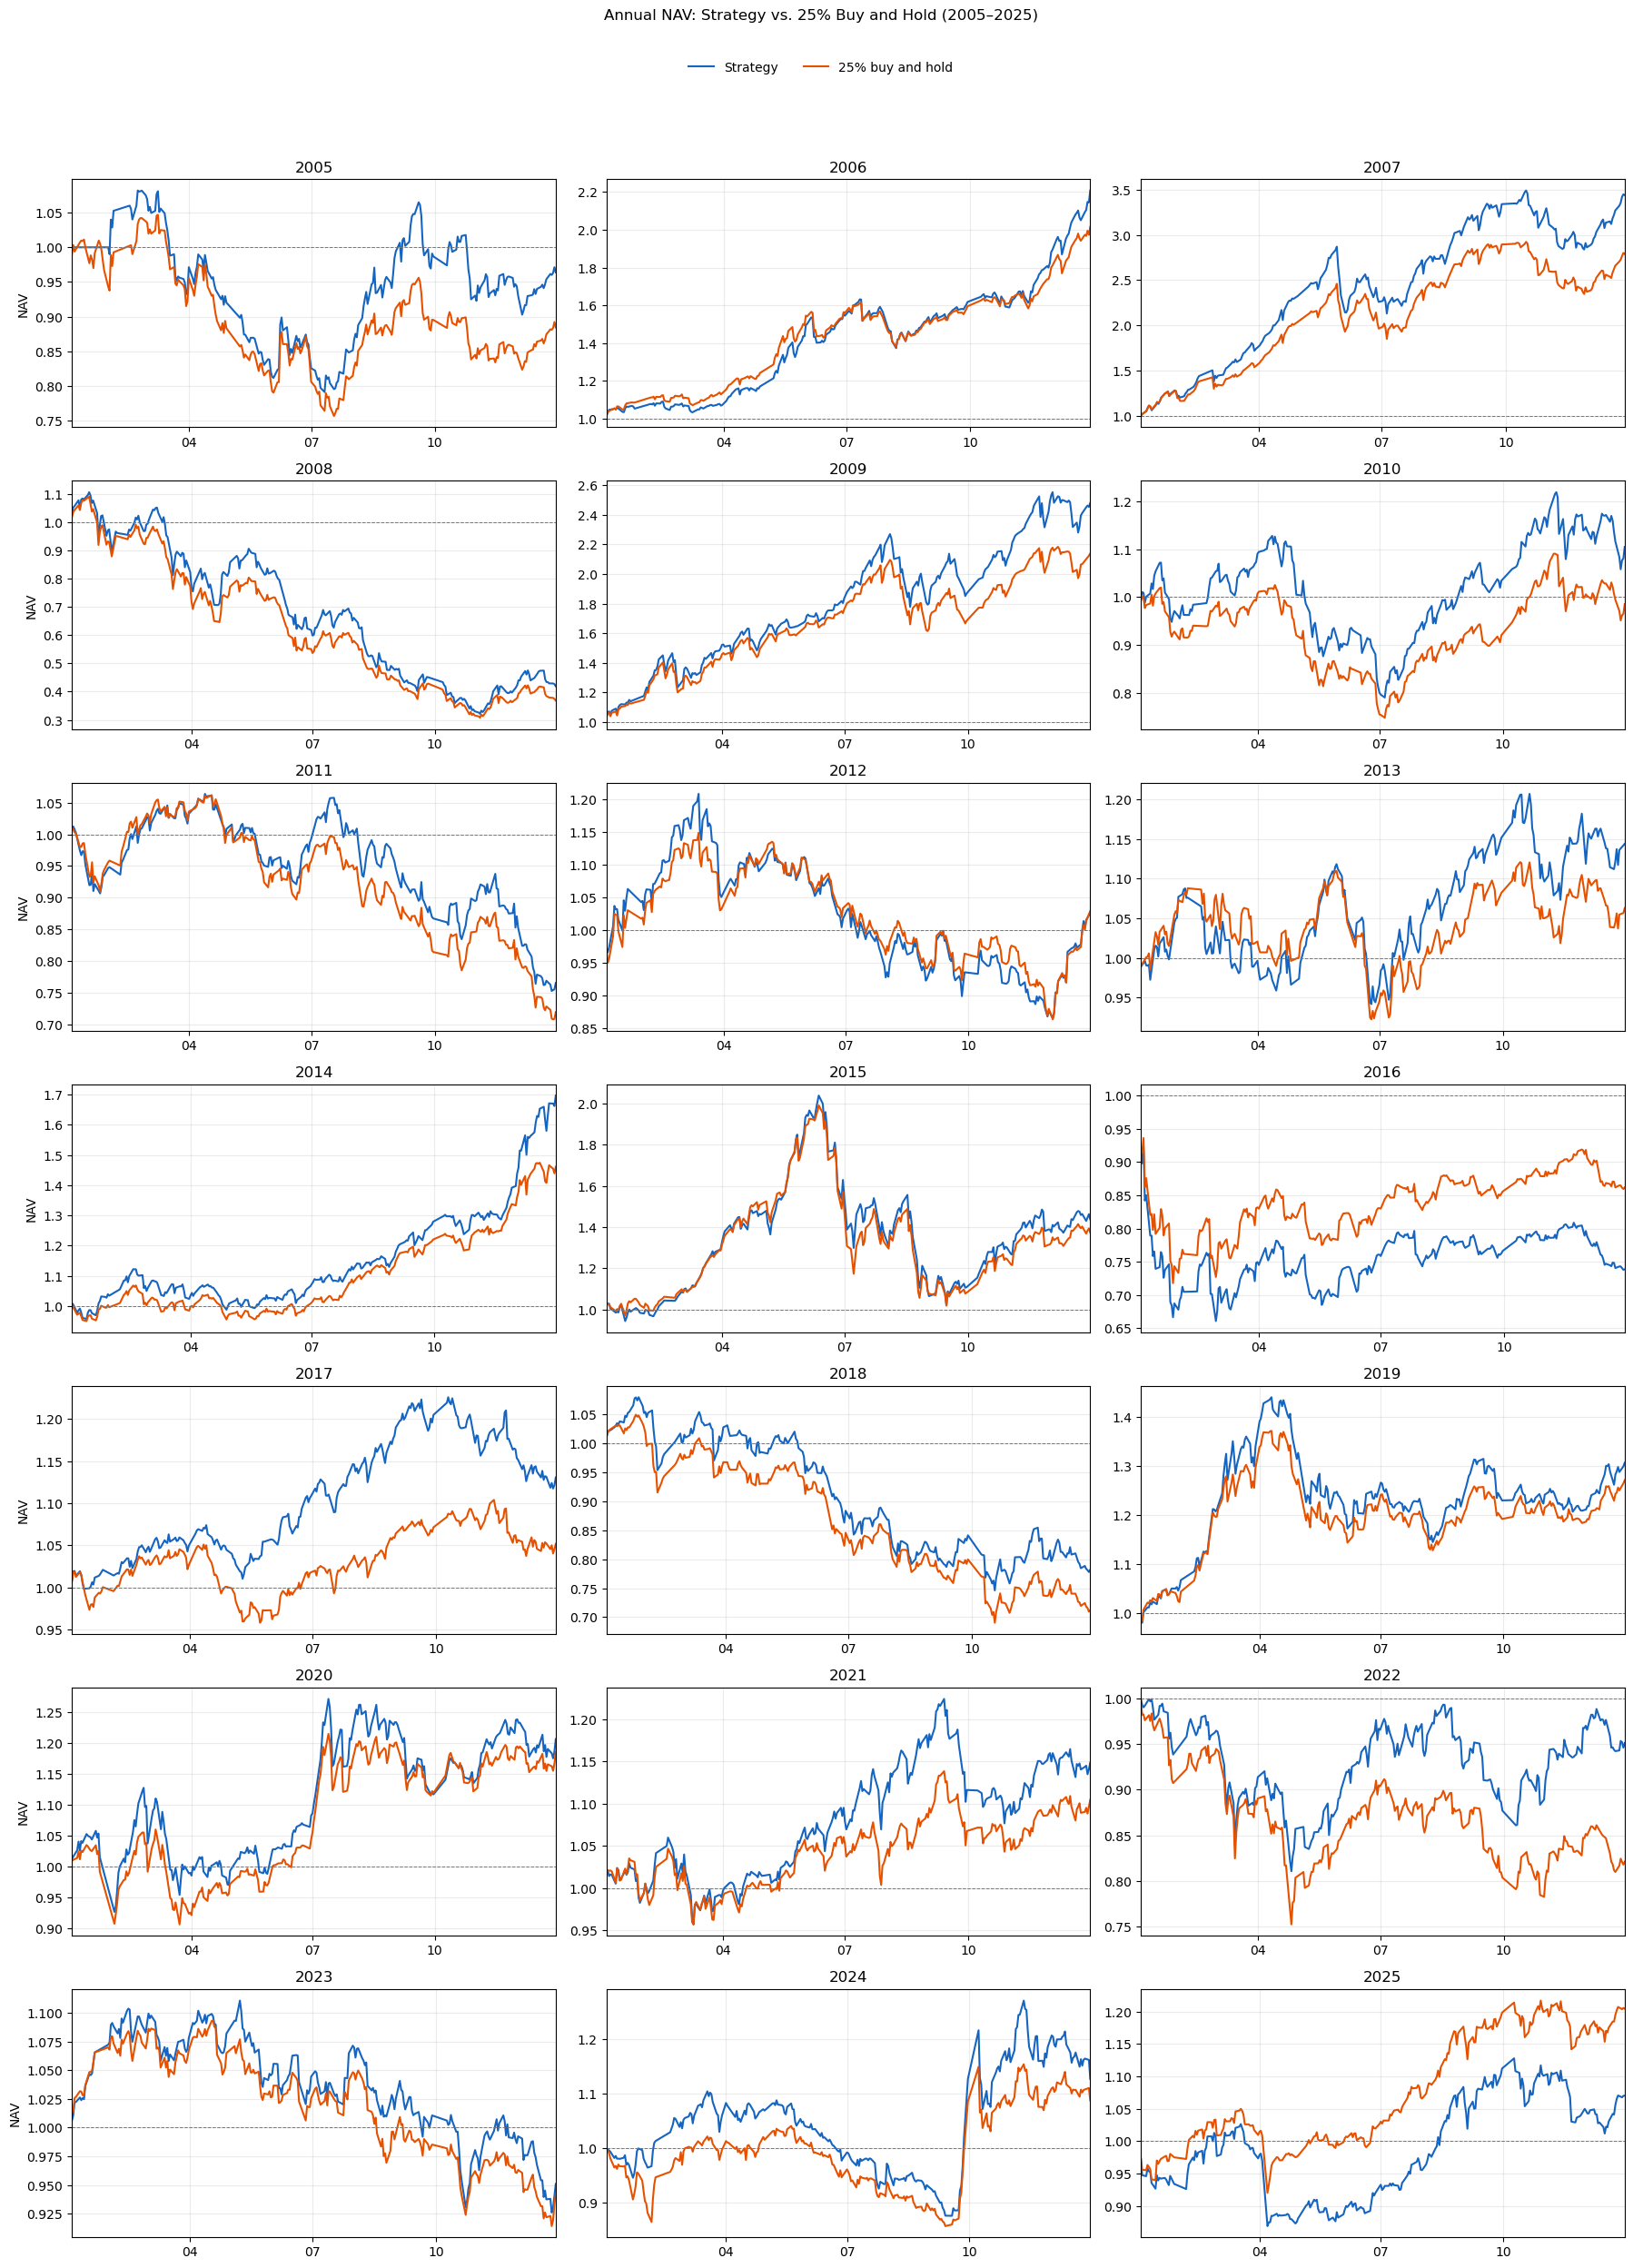

In [35]:
# 每年一个子图；两条曲线均以该年初始资金 1.00 为基准。
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(7, 3, figsize=(18, 25), sharex=False)
for ax, (year, yearly) in zip(axes.flat, comparison_nav.groupby('year', sort=True)):
    ax.plot(yearly['date'], yearly['strategy_nav'], label='Strategy',
            color='#1565C0', linewidth=1.5)
    ax.plot(yearly['date'], yearly['benchmark_nav'], label='25% buy and hold',
            color='#E65100', linewidth=1.5)
    ax.axhline(1.0, color='#777777', linewidth=0.7, linestyle='--')
    ax.set_title(str(year))
    ax.set_xlim(yearly['date'].iloc[0], yearly['date'].iloc[-1])
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%m'))
    ax.grid(alpha=0.25)

for ax in axes[:, 0]:
    ax.set_ylabel('NAV')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.979),
           ncol=2, frameon=False)
fig.suptitle('Annual NAV: Strategy vs. 25% Buy and Hold (2005–2025)', y=0.997)
fig.tight_layout(rect=[0, 0, 1, 0.948])
plt.show()

## 三个跨年区间的累计净值

将上面已经计算的**年度策略及对照组合日收益率**，分别在 2005–2009、2010–2019、2020–2025 三个区间内复利串接；每个区间的起始净值设为 1.00。年度初始资金重置和交易成本的处理仍与上文一致，因此这里展示的是年度回测收益的连续累计曲线。

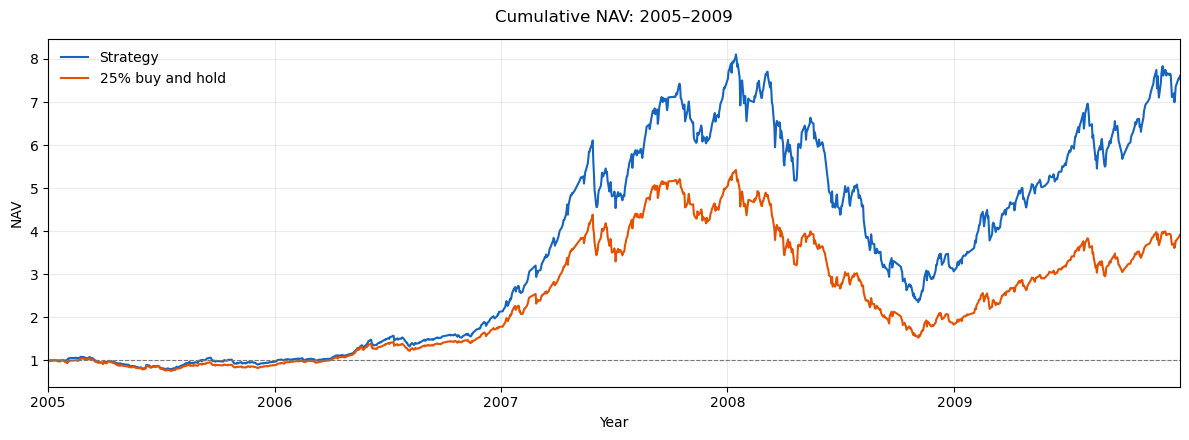

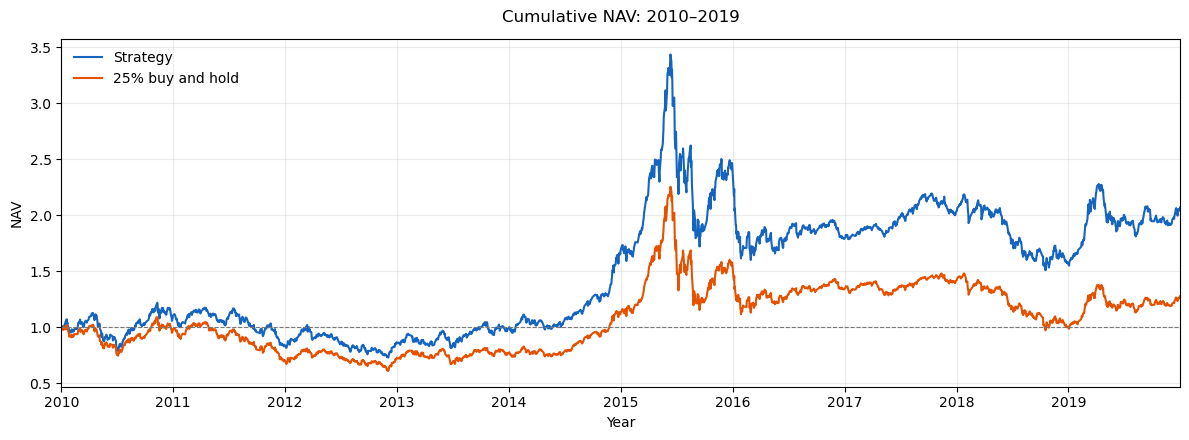

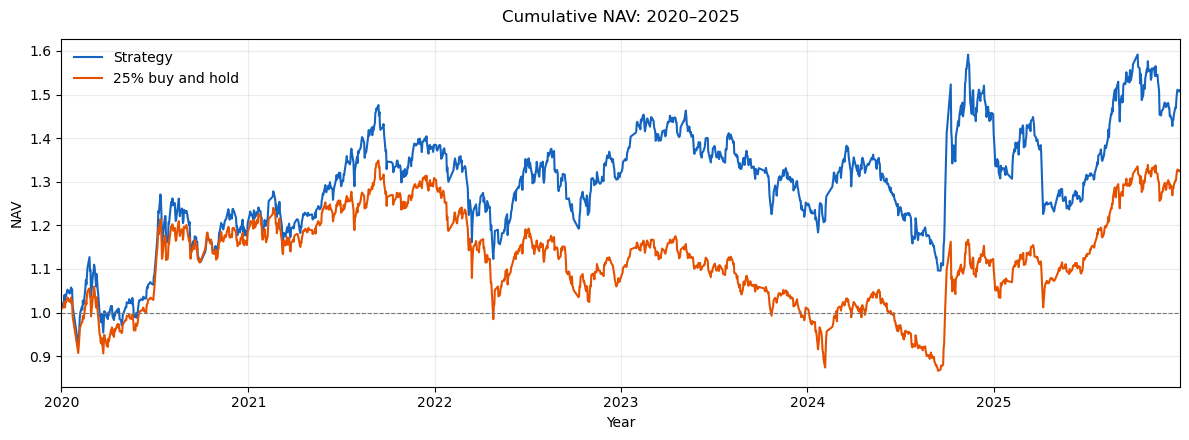

In [36]:
PERIOD_GROUPS = [(2005, 2009), (2010, 2019), (2020, 2025)]
multi_period_frames = []
period_figures = []

for start_year, end_year in PERIOD_GROUPS:
    period_name = f'{start_year}–{end_year}'
    period_data = comparison_nav.loc[
        comparison_nav['year'].between(start_year, end_year)
    ].sort_values('date').copy()
    if period_data.empty:
        raise ValueError(f'{period_name}: 没有交易日数据')

    period_data['period'] = period_name
    period_data['strategy_cum_nav'] = (1.0 + period_data['strategy_return']).cumprod()
    period_data['benchmark_cum_nav'] = (1.0 + period_data['benchmark_return']).cumprod()
    multi_period_frames.append(period_data[
        ['period', 'date', 'strategy_cum_nav', 'benchmark_cum_nav']
    ])

    fig_period, ax = plt.subplots(figsize=(12, 4.5))
    ax.plot(period_data['date'], period_data['strategy_cum_nav'],
            label='Strategy', color='#1565C0', linewidth=1.5)
    ax.plot(period_data['date'], period_data['benchmark_cum_nav'],
            label='25% buy and hold', color='#E65100', linewidth=1.5)
    ax.axhline(1.0, color='#777777', linewidth=0.8, linestyle='--')
    ax.set_title(f'Cumulative NAV: {period_name}', pad=12)
    ax.set_ylabel('NAV')
    ax.set_xlabel('Year')
    ax.set_xlim(pd.Timestamp(f'{start_year}-01-01'), pd.Timestamp(f'{end_year}-12-31'))
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.grid(alpha=0.25)
    ax.legend(loc='upper left', frameon=False)
    fig_period.tight_layout()
    period_figures.append(fig_period)
    plt.show()

multi_period_nav = pd.concat(multi_period_frames, ignore_index=True)